# Agente Virtual de QA · Simulación Monte Carlo del caso de negocio

Este cuaderno corre en Google Colab o en tu computadora. Reconstruye el modelo financiero de 60 meses del caso de negocio, comprueba que reproduce sus cifras y simula 10,000 futuros posibles para responder tres preguntas:

1. ¿Qué probabilidad hay de cumplir cada hito y de recuperar la inversión en cinco años?
2. ¿Cuánta caja puede llegar a necesitar el negocio?
3. ¿Conviene invertir por etapas?

Todo corre en segundos y **no llama a ninguna API**. El tablero interactivo con las mismas cifras está en `dashboard/app.py`.

In [1]:
# En Colab: clona el repositorio e instala lo necesario. En tu computadora, abre el cuaderno desde la raíz del repositorio.
import sys, os
if "google.colab" in sys.modules:
    !git clone -q https://github.com/SiriusDarkz/AgenteQA.git
    %cd AgenteQA
    !pip install -q -r dashboard/requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

## 1. El modelo reproduce el caso de negocio

Las pruebas de `simulacion/pruebas/test_modelo.py` validan año por año ingresos, resultados, caja, VAN y TIR. Aquí, la versión corta: los tres escenarios principales.

In [2]:
import math
from simulacion.modelo import correr_escenario
publicado = {"base": (991_523, 35, 60), "conservador": (1_498_616, 53, None), "optimista": (685_568, 29, 44)}
mes = lambda m: "no recupera en 60 meses" if m is None or (isinstance(m, float) and math.isnan(m)) else f"mes {int(m)}"
for nombre, (necesidad, equilibrio, recuperacion) in publicado.items():
    i = correr_escenario(nombre)["indicadores"]
    print(f"{nombre:12s} necesidad de caja USD {i['necesidad_maxima']:>10,.0f} (caso: {necesidad:,}) · "
          f"equilibrio mes {i['mes_equilibrio']:.0f} (caso: {equilibrio}) · recuperación: {mes(i['mes_recuperacion'])} (caso: {mes(recuperacion)})")

base         necesidad de caja USD    991,523 (caso: 991,523) · equilibrio mes 35 (caso: 35) · recuperación: mes 60 (caso: mes 60)
conservador  necesidad de caja USD  1,500,006 (caso: 1,498,616) · equilibrio mes 52 (caso: 53) · recuperación: no recupera en 60 meses (caso: no recupera en 60 meses)
optimista    necesidad de caja USD    685,568 (caso: 685,568) · equilibrio mes 29 (caso: 29) · recuperación: mes 44 (caso: mes 44)


## 2. Diez mil futuros posibles

In [3]:
import time
from simulacion import montecarlo
t = time.perf_counter()
res = montecarlo.correr()                       # 10,000 corridas, semilla fija 20261026
a = montecarlo.analizar(res)
r = a["resumen"]
print(f"Listo en {time.perf_counter() - t:.1f} s")
print("Probabilidad de cumplir cada hito:", [f"{p:.0%}" for p in r["prob_hito"]], "· los cuatro:", f"{r['prob_todos_los_hitos']:.0%}")
print(f"Recuperar la inversión en 60 meses: {r['prob_recupera_60']:.0%}")
print(f"Necesidad de caja: mediana USD {r['necesidad_maxima']['p50']:,.0f} · P90 USD {r['necesidad_maxima']['p90']:,.0f}")
print(f"VAN con valor terminal positivo: {r['prob_van_con_vt_positivo']:.0%}")

Listo en 1.9 s
Probabilidad de cumplir cada hito: ['50%', '57%', '50%', '55%'] · los cuatro: 18%
Recuperar la inversión en 60 meses: 34%
Necesidad de caja: mediana USD 1,132,275 · P90 USD 1,630,104
VAN con valor terminal positivo: 64%


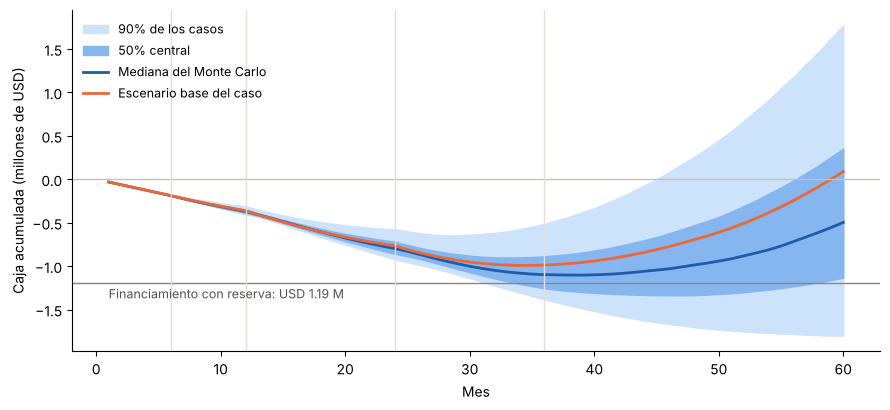

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from simulacion.modelo import simular
b = a["bandas_caja"]; meses = np.arange(1, 61); m = lambda v: np.array(v) / 1e6
base = simular(n=1)["caja"][0]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(meses, m(b["p5"]), m(b["p95"]), color="#cde2fb", label="90% de los casos")
ax.fill_between(meses, m(b["p25"]), m(b["p75"]), color="#86b6ef", label="50% central")
ax.plot(meses, m(b["p50"]), color="#1c5cab", lw=2, label="Mediana del Monte Carlo")
ax.plot(meses, base / 1e6, color="#eb6834", lw=2, label="Escenario base del caso")
ax.axhline(0, color="#c3c2b7", lw=1); ax.axhline(-1.19, color="#898781", lw=1)
ax.text(1, -1.23, "Financiamiento con reserva: USD 1.19 M", va="top", fontsize=9, color="#52514e")
for x in (6, 12, 24, 36): ax.axvline(x, color="#e1e0d9", lw=1)
ax.set_xlabel("Mes"); ax.set_ylabel("Caja acumulada (millones de USD)")
for lado in ("top", "right"): ax.spines[lado].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=9); plt.tight_layout(); plt.show()

## 3. ¿Conviene invertir por etapas?

In [5]:
import pandas as pd
pd.DataFrame([{"Regla": p["regla"], "VAN esperado (USD M)": round(p["van_con_vt_esperado"] / 1e6, 2),
               "Capital expuesto promedio (USD M)": round(p["capital_expuesto_medio"] / 1e6, 2),
               "Negocios buenos detenidos": f"{p['buenos_detenidos']:.0%}", "Negocios malos detenidos": f"{p['malos_detenidos']:.0%}"}
              for p in a["politicas"]])

,Regla,VAN esperado (USD M),Capital expuesto promedio (USD M),Negocios buenos detenidos,Negocios malos detenidos
0,Todo de una vez (sin compuertas),0.94,1.17,0%,0%
1,Etapas del caso: hitos 1 a 4,0.20,0.43,62%,93%
2,"Hito 1 con un piloto que pague, hitos 2 a 4",0.39,0.60,39%,88%
3,Solo los hitos de ARR (2 a 4),0.47,0.67,30%,86%
4,Solo el hito 3 (ARR del mes 24),0.63,0.90,13%,70%


**Cómo leerlo.** Invertir por etapas reduce mucho el capital expuesto, pero la regla del hito 1 del caso («dos de tres pilotos pagan») detiene seis de cada diez negocios que sí recuperarían la inversión. Relajarla a «al menos un piloto paga» conserva más valor esperado a cambio de exponer algo más de capital. El hito 3 (ARR del mes 24) es la señal más confiable para decidir.